# Problem 2 · Heart rate from a fingertip video

**MPHY0058 · Signal and Image Processing.** Estimate heart rate from the changing brightness of the finger in `video_of_finger.MOV`. Every decoded frame contributes one measurement.

The saved outputs can be viewed immediately. The accompanying CSV contains the measured frame means and timestamps so the plots and heart-rate calculation can also be rerun without the video. To reproduce them, place the supplied video at `data/video_of_finger.MOV` and run all cells in order. The Python dependencies are NumPy, Matplotlib and imageio-ffmpeg. The last package supplies the video decoder.

In [3]:
from pathlib import Path

import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np

video_path = Path("data/video_of_finger.MOV")
out = Path("problem2_outputs")
out.mkdir(exist_ok=True)

## 2.1 · Convert each frame to a mean grayscale value

FFmpeg decodes each frame as 8-bit grayscale (0–255). NumPy averages all its pixels, producing one number per frame. The presentation timestamp indicates when the frame was displayed. Using the original timestamps preserves small variations in the time between frames.

In [4]:
def read_video_signal(video_path, output_dir):
    """Return elapsed presentation times (s), full-frame mean grayscale, and frame size."""
    if not video_path.is_file():
        raise FileNotFoundError(f"Place the coursework video at {video_path.resolve()}")
    # Save one timestamp per decoded frame, preserving the input cadence.
    timing_file = output_dir / "frame_times.txt"
    timing_filter = ("metadata=mode=add:key=pulseframe:value=1,"
                     f"metadata=mode=print:key=pulseframe:file={timing_file.as_posix()}")
    frames = imageio_ffmpeg.read_frames(
        str(video_path), pix_fmt="gray", bits_per_pixel=8,
        input_params=["-noautorotate"],
        output_params=["-vf", timing_filter, "-fps_mode", "passthrough"],
    )
    try:
        metadata = next(frames)
        width, height = metadata["size"]
        means = []
        for frame in frames:
            pixels = np.frombuffer(frame, dtype=np.uint8)
            if pixels.size != width * height:
                raise ValueError("Incomplete grayscale frame.")
            means.append(pixels.mean())
    finally:
        frames.close()

    times = []
    for line in timing_file.read_text().splitlines():
        if line.startswith("frame:"):
            times.append(float(line.split("pts_time:")[1].strip()))
    times = np.asarray(times, dtype=float)
    if len(times) != len(means) or len(times) < 3:
        raise ValueError("Expected one timestamp for every decoded frame.")
    if not np.all(np.isfinite(times)) or np.any(np.diff(times) <= 0):
        raise ValueError("Video timestamps must be finite and strictly increasing.")
    return times - times[0], np.asarray(means), (width, height)


means_file = out / "frame_means.csv"
if video_path.is_file():
    time_s, gray, size = read_video_signal(video_path, out)
    print(f"Decoded video: {size[0]} x {size[1]} pixels per frame")
    np.savetxt(means_file, np.column_stack((time_s, gray)), delimiter=",",
               header="time_s,mean_grayscale", comments="", fmt="%.10f")
elif means_file.is_file():
    time_s, gray = np.loadtxt(means_file, delimiter=",", skiprows=1, unpack=True)
    print("Loaded saved whole-frame measurements from the supplied video.")
else:
    raise FileNotFoundError("Provide the original video or the bundled frame_means.csv.")

n = len(gray)
span = time_s[-1] - time_s[0]
fs = (n - 1) / span
print(f"{n:,} frames")
print(f"First-to-last frame span: {span:.3f} s | Effective sampling rate: {fs:.3f} Hz")
print(f"Frame interval: {1000*np.diff(time_s).min():.2f}–{1000*np.diff(time_s).max():.2f} ms")

Decoded video: 1920 x 1080 pixels per frame
1,852 frames
First-to-last frame span: 61.745 s | Effective sampling rate: 29.978 Hz
Frame interval: 33.33–35.00 ms


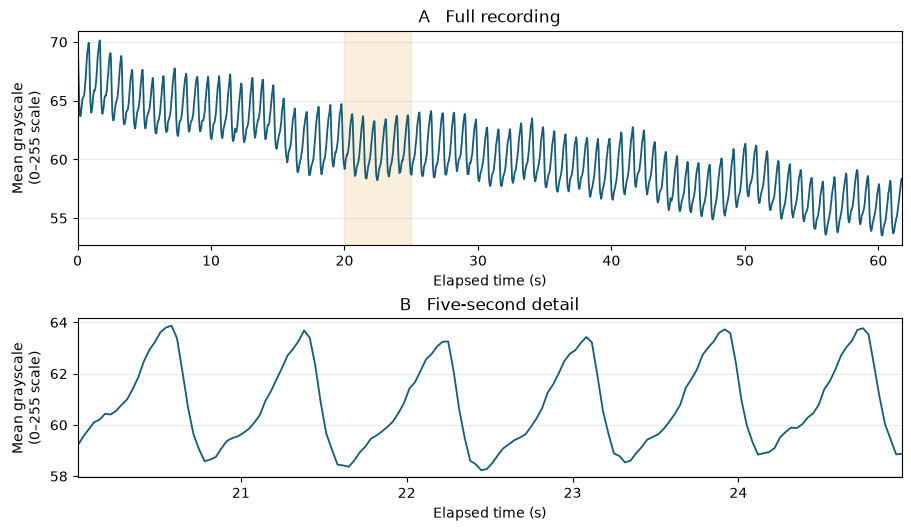

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), layout="constrained",
                         gridspec_kw={"height_ratios": [1.35, 1]})
zoom = (time_s >= 20) & (time_s <= 25)
for ax, selection, title in [
    (axes[0], np.ones(n, dtype=bool), "A   Full recording"),
    (axes[1], zoom, "B   Five-second detail"),
]:
    ax.plot(time_s[selection], gray[selection], color="#145C78", linewidth=1.3)
    ax.set(title=title, xlabel="Elapsed time (s)", ylabel="Mean grayscale\n(0–255 scale)")
    ax.set_xlim(time_s[selection][0], time_s[selection][-1])
    ax.grid(axis="y", alpha=0.25)
axes[0].axvspan(20, 25, color="#E7AB55", alpha=0.2)
fig.savefig(out / "problem2_grayscale.png", dpi=180)
plt.show()

## 2.2 · Estimate heart rate from the optical pulse

Interpolation onto an equally spaced time grid allows the FFT to use one sampling frequency. Subtracting the mean removes the constant brightness offset. A Hann window reduces leakage from the finite record. We select the strongest frequency in the same broad search range used in Problem 1 (0.5–3.5 Hz, or 30–210 bpm). This range excludes slow baseline drift. Multiplying the peak frequency by 60 converts cycles per second to beats per minute.

In [6]:
uniform_time = np.linspace(time_s[0], time_s[-1], n)
uniform_gray = np.interp(uniform_time, time_s, gray)
centred = uniform_gray - uniform_gray.mean()
window = np.hanning(n)
freq = np.fft.rfftfreq(n, d=1/fs)
amplitude = np.abs(np.fft.rfft(centred * window)) / window.sum()
amplitude[1:] *= 2
if n % 2 == 0:
    amplitude[-1] /= 2  # The Nyquist bin appears only once.

low_hz, high_hz = 0.5, 3.5
candidates = np.flatnonzero((freq >= low_hz) & (freq <= high_hz))
peak = candidates[np.argmax(amplitude[candidates])]
peak_hz = freq[peak]
heart_rate = 60 * peak_hz
print(f"Dominant frequency: {peak_hz:.4f} Hz | Heart rate: {heart_rate:.2f} bpm")
print(f"FFT bin spacing: {fs/n:.5f} Hz, equivalent to {60*fs/n:.2f} bpm")
np.savetxt(out / "problem2_spectrum.csv", np.column_stack((freq, amplitude)), delimiter=",",
           header="frequency_hz,one_sided_grayscale_amplitude", comments="")

Dominant frequency: 1.1978 Hz | Heart rate: 71.87 bpm
FFT bin spacing: 0.01619 Hz, equivalent to 0.97 bpm


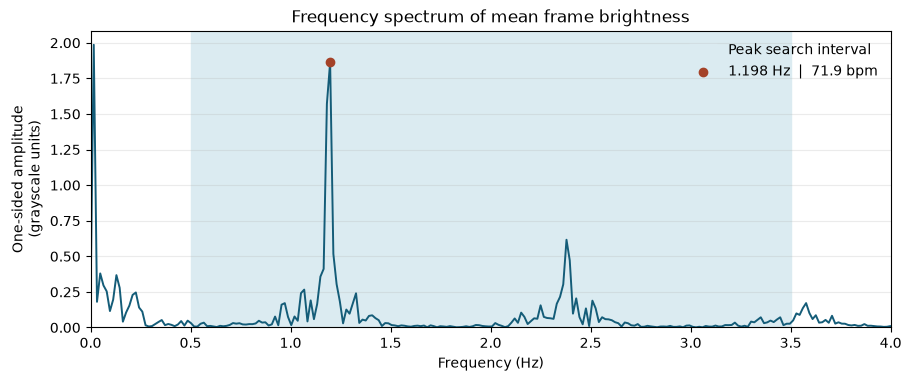

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.7), layout="constrained")
ax.axvspan(low_hz, high_hz, color="#DBEBF1", label="Peak search interval")
ax.plot(freq, amplitude, color="#145C78", linewidth=1.4)
ax.scatter(peak_hz, amplitude[peak], color="#A44228", zorder=3,
           label=f"{peak_hz:.3f} Hz  |  {heart_rate:.1f} bpm")
ax.set(xlim=(0, 4), ylim=(0, None), title="Frequency spectrum of mean frame brightness",
       xlabel="Frequency (Hz)", ylabel="One-sided amplitude\n(grayscale units)")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.savefig(out / "problem2_spectrum.png", dpi=180)
plt.show()

## Check the pulse period

Autocorrelation compares the signal with a delayed copy. The strongest local maximum in the allowed period range gives a second estimate using waveform repetition. This also helps distinguish the main pulse from a harmonic.

In [6]:
acf = np.correlate(centred, centred, mode="full")[n-1:]
lag_s = np.arange(n) / fs
maxima = np.flatnonzero((acf[1:-1] > acf[:-2]) & (acf[1:-1] >= acf[2:])) + 1
possible = maxima[(lag_s[maxima] >= 1/high_hz) & (lag_s[maxima] <= 1/low_hz)]
if not possible.size:
    raise ValueError("No autocorrelation peak in the selected period range.")
best = possible[np.argmax(acf[possible])]
period = lag_s[best]
check_rate = 60 / period
print(f"Repeat period: {period:.3f} s ({best} frames on the uniform grid)")
print(f"Time-domain estimate: {check_rate:.2f} bpm")
print(f"Mean grayscale in the first and last 5 s: "
      f"{gray[time_s < 5].mean():.1f} and {gray[time_s > span-5].mean():.1f}")

Repeat period: 0.834 s (25 frames on the uniform grid)
Time-domain estimate: 71.95 bpm
Mean grayscale in the first and last 5 s: 65.9 and 56.0


## Interpretation

The whole-frame grayscale signal contains repeating pulses superimposed on a declining baseline. Mean brightness fell from 65.9 in the first five seconds to 56.0 in the last five. The dominant frequency was **1.1978 Hz**, equivalent to **71.87 bpm**. The waveform repeated every **0.834 s**, giving **71.95 bpm** by autocorrelation. A smaller peak near 2.38 Hz is consistent with a second harmonic.

These two estimates agree to within the FFT bin spacing of 0.97 bpm. Both depend on the same video. Changes in finger pressure, movement or camera exposure could affect the brightness, and the recording alone cannot distinguish their contributions. A simultaneous reference measurement would allow the heart-rate error to be quantified.

**AI use.** OpenAI ChatGPT (GPT-6.2-astra, Codex) assisted with coding, running the video analysis, plotting and drafting this interpretation. Record any subsequent edits and checks by the group in the submitted declaration.